In [41]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, asdict
from typing import Optional, Dict, Tuple
from utilities import make_frequency_grid, rho_shear, ShearParams

In [51]:

def sample_shear_params(T=1.0, rng=np.random.default_rng()) -> ShearParams:
    """
    Randomly sample physically plausible mock shear spectral parameters.
    All frequencies are in units of T.
    """
    A=rng.uniform(10.0, 14.0)
    #A = rng.uniform(0.02, 0.4)          # controls viscosity
    Gamma = rng.integers(1,5)
    #Gamma = rng.uniform(0.2, 4.0)       # transport width
    B = rng.uniform(2e-3, 2e-2)         # UV amplitude
    Lambda_uv = rng.uniform(2.0, 6.0)
    sharpness_uv = rng.uniform(2.0, 8.0)

    n_bumps = rng.integers(0, 3)        # 0, 1, or 2 bumps

    if n_bumps > 0:
        bump_amps = rng.uniform(1e-3, 5e-2, size=n_bumps)
        bump_mus = rng.uniform(1.0, 8.0, size=n_bumps)
        bump_sigmas = rng.uniform(0.2, 1.5, size=n_bumps)
    else:
        bump_amps = np.array([])
        bump_mus = np.array([])
        bump_sigmas = np.array([])

    return ShearParams(
        A=A,
        #Gamma=Gamma,
        Gamma=1.0,
        B=B,
        Lambda_uv=Lambda_uv,
        sharpness_uv=sharpness_uv,
        n_bumps=n_bumps,
        bump_amps=bump_amps,
        bump_mus=bump_mus,
        bump_sigmas=bump_sigmas,
        T=T
    )


def generate_random_shear_spectrum(w, T=1.0, rng=np.random.default_rng()):
    params = sample_shear_params(T=T, rng=rng)
    rho = rho_shear(w, params)
    return rho, params

params1 = ShearParams(A=12.15, Gamma=1.0, B=0.023, Lambda_uv=2.0, sharpness_uv=2.0)

rr = rho_shear(w, params1)

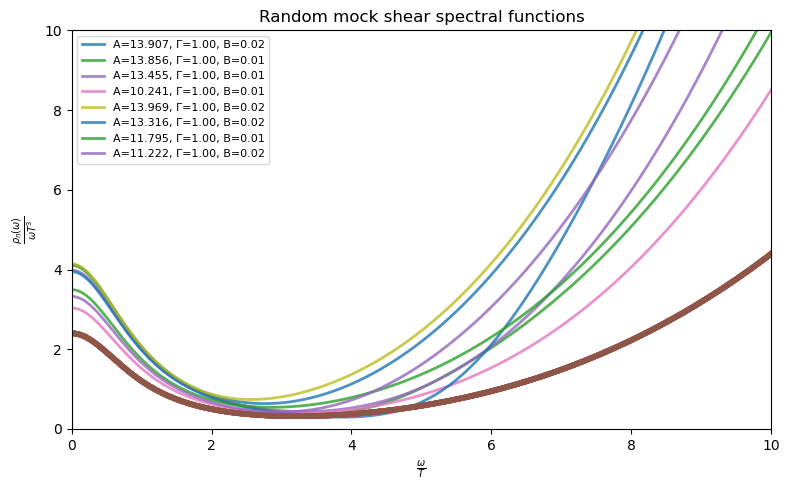

In [52]:
if __name__ == "__main__":
    rng = np.random.default_rng(1234)

    # Frequency grid x = omega/T
    w = make_frequency_grid()

    # ----- Shear examples -----
    plt.figure(figsize=(8, 5))
    for _ in range(8):
        rho, params = generate_random_shear_spectrum(w, T=1.5, rng=rng)
        plt.plot(w, rho/(w*(params.T**4)), lw=2, alpha=0.8, label=f"A={params.A:.3f}, Γ={params.Gamma:.2f}, B={params.B:.2f}")
        plt.plot(w, rr/(w*(params.T**4)), lw=4, alpha=1)

    plt.xlim(0,10)
    plt.ylim(0,10)
    
    plt.xlabel(r"$\frac{\omega}{T}$")
    plt.ylabel(r"$\frac{\rho_\eta(\omega)}{\omega T^3}$")
    plt.title("Random mock shear spectral functions")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()